# Supplemental Figure 7, panel A

i. MA plots showing change in nascent transcription (BAFinh vs vehicle; PRO-seq) by cRE class
ii. Bar plot showing number of significantly differentially transcribed cREs by cRE class

*Outputs: PanelA.pdf, PanelA_counts.pdf*

# Setup

In [1]:
library(tidyverse)
library(here)
library(ggrastr)
library(patchwork)
here::i_am("figures/SuppFig7/PanelA/PanelA.ipynb")
sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] patchwork_1.3.0 ggrastr_1.0.2   here_1.0.2      lubridate_1.9.4
 [5] forcats_1.0.0   stringr_1.5.1   dplyr_1.1.4     purrr_1.0.2    
 [9] readr_2.1.5     tidyr_1.3.1     tibble_3.2.1    ggplot2_3.5.2  
[13] tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] vipor_0.4.7      

# Load data

In [4]:
pro_bafinh <- read.delim(
    here("inputs", "countmat", "PROseq_eRNA", "BAFinh_v_Veh_PROseq_cRE.tsv"), sep='\t')

# Generate MA plots

Saving 7 x 7 in image


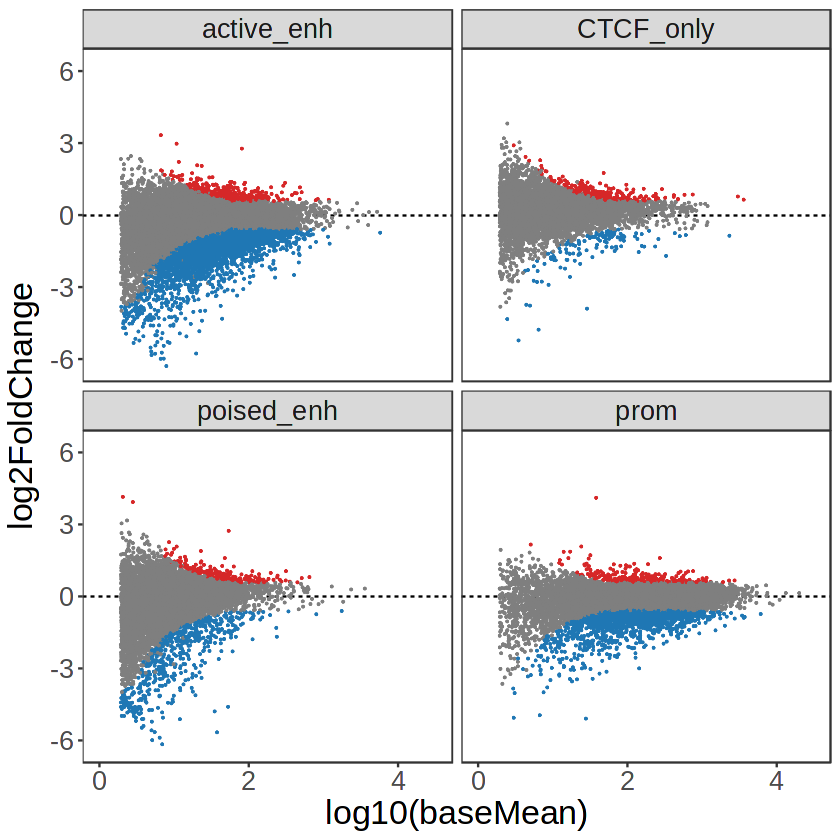

In [33]:
pro_bafinh %>% 
    filter(type %in% c("active_enh", "poised_enh", "prom", "CTCF_only")) %>%
    na.omit() %>%
    ggplot(aes(x=log10(baseMean), y=log2FoldChange, color=change)) + 
    geom_hline(yintercept=0,linetype=2) + 
    rasterize(geom_point(show.legend=FALSE, size=.25), dpi=300) + 
    scale_y_continuous(limits=c(-6.3,6.3),breaks=seq(-6,6,by=3)) + 
    scale_x_continuous(limits=c(0,4.5), breaks=seq(0,4,by=2)) +
    scale_color_manual(values=c("up" = "#D62728", "down" = "#1F77B4", "nc" = "gray70")) +
    theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=20)) + facet_wrap(~type)

ggsave("PanelA.pdf")

# summarize counts of differentially transcribed cREs

In [29]:
n_table <- pro_bafinh %>% 
    filter(type %in% c("active_enh", "poised_enh", "prom", "CTCF_only")) %>%
    na.omit() %>% group_by(type, change) %>% summarize(n=n()) %>%
    filter(change!="ns")

`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.


# generate barplot

Warning message:
“Removed 4 rows containing missing values or values outside the scale range
(`geom_col()`).”
Warning message:
“Removed 4 rows containing missing values or values outside the scale range
(`geom_col()`).”


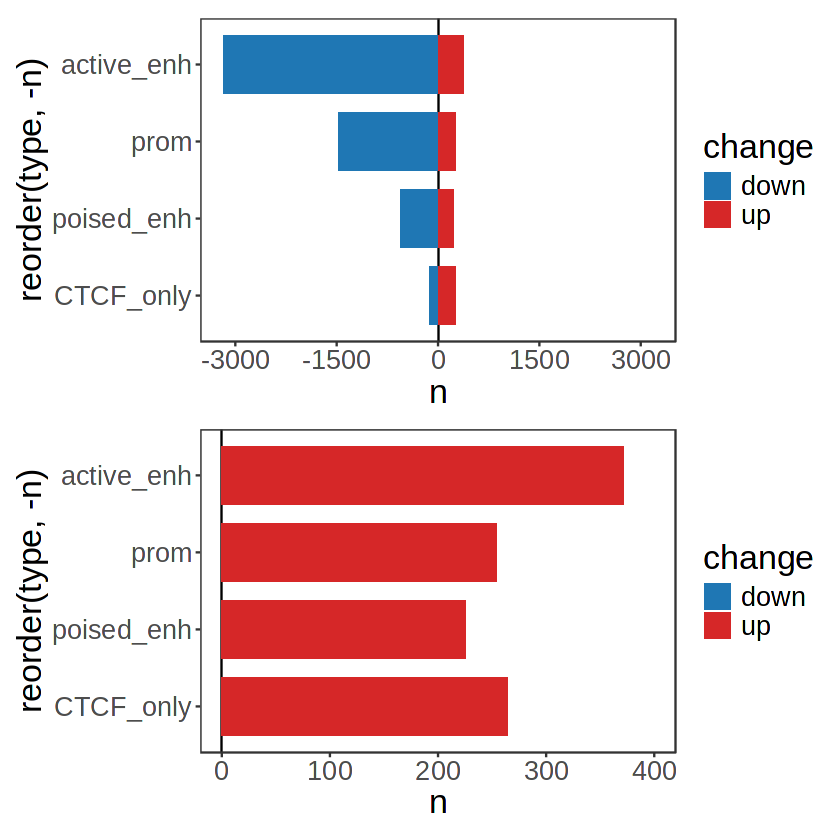

In [56]:
p1 <- n_table %>%
    mutate(n=ifelse(change=="up", n, -n)) %>%
    ggplot(aes(y=reorder(type,-n), x=n, fill=change)) +
    geom_vline(xintercept=0) +
    geom_col(width=.75) +
    theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=20)) +
    scale_x_continuous(limits=c(-3200,3200), breaks=seq(-3000,3000,by=1500)) +
    scale_fill_manual(values=c("up" = "#D62728", "down" = "#1F77B4"))

p2 <- n_table %>%
    mutate(n=ifelse(change=="up", n, -n)) %>%
    ggplot(aes(y=reorder(type,-n), x=n, fill=change)) +
    geom_vline(xintercept=0) +
    geom_col(width=.75) +
    theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=20)) +
    scale_x_continuous(limits=c(0,400)) +
    scale_fill_manual(values=c("up" = "#D62728", "down" = "#1F77B4")) 
p1 / p2
ggsave("PanelA_counts.pdf", height=5, width=5)

In [32]:
write.table(n_table,"n_diff.tsv", sep='\t', quote=F, row.names=F)